In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Load Household Power Consumption Dataset

In this section, we load the **Household Power Consumption** dataset using `pandas`.

The dataset contains household electricity consumption measurements recorded at one-minute intervals.

When loading the dataset:
- The columns are separated using `;`.
- The `?` character is treated as a missing value.

In [2]:
power_ds = pd.read_csv("/mnt/c/Machine Learning & Deep Learning/datasets/household_power_consumption.txt", 
                       sep= ';', na_values= ['?'])
power_ds.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Dataset Information

In this step, we use the `info()` method to examine the overall structure of the dataset, including the number of observations, columns, and data types.

The dataset contains **2,075,259 records** and **9 columns**.

The columns can be categorized as follows:
- `Date` and `Time` are stored as strings.
- The remaining 7 columns contain numerical measurements stored as `float64`.

In [3]:
power_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


## Missing Values

In this step, we check the percentage of missing values in each column.

We calculate the mean of `isna()` for each column and multiply it by 100 to obtain the percentage of missing values.

This analysis helps us understand the quality of the dataset before performing **data preprocessing** and **modeling**.

In [4]:
power_ds.isna().mean() * 100

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

### Value Frequency Analysis

The `value_counts()` method is used to examine the frequency of each unique value in the `Global_active_power` column.

This helps identify the most frequent power consumption values and provides an overview of how the data is distributed.

In [5]:
power_ds['Global_active_power'].value_counts()

Global_active_power
0.218    9565
0.216    9363
0.322    9350
0.324    9304
0.326    9187
         ... 
9.724       1
9.656       1
9.630       1
9.648       1
8.600       1
Name: count, Length: 4186, dtype: int64

### Outlier Detection Using the IQR Method

The **Interquartile Range (IQR)** method is used to identify potential outliers in the `Global_active_power` column.

- **Q1 (25th percentile):** Represents the lower quartile.
- **Q3 (75th percentile):** Represents the upper quartile.
- **IQR:** Calculated as `Q3 - Q1`.
- **Lower Bound:** `Q1 - 1.5 × IQR`
- **Upper Bound:** `Q3 + 1.5 × IQR`

Any value below the lower bound or above the upper bound is considered a potential outlier.

In this dataset, **94,907 observations** are identified as potential outliers using this method.

In [6]:
q1 = power_ds['Global_active_power'].quantile(0.25)
q3 = power_ds['Global_active_power'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = power_ds[(power_ds['Global_active_power'] < lower_bound) | (power_ds['Global_active_power'] > upper_bound)]
print(len(outliers))
print(outliers['Global_active_power'])

94907
0          4.216
1          5.360
2          5.374
3          5.388
4          3.666
           ...  
2074573    3.632
2074574    3.616
2074575    3.632
2074576    3.552
2074577    3.552
Name: Global_active_power, Length: 94907, dtype: float64


### Descriptive Statistics

The `describe()` method is used to obtain a statistical summary of the `Global_active_power` column.

It provides key statistics such as the count, mean, standard deviation, minimum, quartiles, and maximum values. This helps us understand the overall distribution and variability of the power consumption data.

In [7]:
power_ds['Global_active_power'].describe()

count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

### Skewness Analysis

The skewness of numerical features is analyzed to determine an appropriate method for handling missing values.

To avoid repeating the same conditional logic for each feature, a reusable function was defined. The function calculates the skewness of a given column and automatically recommends either **mean** or **median** imputation based on the distribution's skewness.

For approximately symmetric distributions, the function recommends **mean imputation**. For moderately or highly skewed distributions, it recommends **median imputation**, as the median is more robust to extreme values and outliers.

For `Global_active_power`, the calculated skewness is approximately **1.81**, indicating a positively skewed distribution. Therefore, the function recommends **median imputation**.

In [8]:
def checked_how_to_impute_nan_values (column_name):
    check_skew = column_name.skew()
    print(check_skew)
    if check_skew >= 1 or check_skew <= -1:
        print("Use Median for imputation")
    elif -0.5 <= check_skew <= 0.5:
        print("Use Mean for imputation")
    elif (-1 < check_skew < -0.5) or (0.5 < check_skew < 1):
        print("Use Median for imputation")

In [9]:
checked_how_to_impute_nan_values(power_ds['Global_active_power'])

1.7862333920915974
Use Median for imputation


### Missing Value Imputation

Since `Global_active_power` is positively skewed and contains potential outliers, the **median** is used to replace its missing values.

After imputation, the percentage of missing values in each column is calculated again to verify that the missing values in `Global_active_power` have been successfully handled.

In [10]:
power_ds['Global_active_power'] = power_ds['Global_active_power'].fillna(power_ds['Global_active_power'].median())

In [11]:
power_ds.isna().mean() * 100

Date                     0.000000
Time                     0.000000
Global_active_power      0.000000
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

### Descriptive Statistics — `Voltage`

The `describe()` method is used to examine the statistical characteristics of the `Voltage` feature.

The results show that the voltage is centered around **240.84 V**, with a median of approximately **241.01 V** and a standard deviation of **3.24 V**.

The middle 50% of the observations are between **238.99 V** and **242.89 V**, while the minimum and maximum values are **223.20 V** and **254.15 V**, respectively.

Overall, the relatively small standard deviation indicates that the voltage values are concentrated within a narrow range.

In [12]:
power_ds['Voltage'].describe()

count    2.049280e+06
mean     2.408399e+02
std      3.239987e+00
min      2.232000e+02
25%      2.389900e+02
50%      2.410100e+02
75%      2.428900e+02
max      2.541500e+02
Name: Voltage, dtype: float64

### Statistical Outlier Analysis — `Voltage`

The **Interquartile Range (IQR)** method is used to identify potential statistical outliers in the `Voltage` feature.

The analysis identifies **51,067 observations** as potential outliers according to the 1.5 × IQR rule.

However, these observations are not automatically considered incorrect or invalid. The detected values are still within a plausible voltage range, with values such as **232–233 V** and a maximum of **254.15 V**.

Therefore, the statistical outliers are **kept in the dataset** rather than removed. The IQR method is used here to identify unusual observations, not to automatically classify them as erroneous measurements.

For this time-series dataset, sudden changes relative to neighboring time points may provide a more meaningful way to investigate abnormal voltage readings in later stages.

In [13]:
q1 = power_ds['Voltage'].quantile(0.25)
q3 = power_ds['Voltage'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = power_ds[(power_ds['Voltage'] < lower_bound) | (power_ds['Voltage'] > upper_bound)]
print(len(outliers))
print(outliers['Voltage'])

51067
10         232.86
11         232.78
12         232.99
13         232.91
20         232.69
            ...  
2072414    232.71
2073685    232.96
2073686    232.98
2073689    233.10
2074342    249.01
Name: Voltage, Length: 51067, dtype: float64


### Missing Value Imputation — `Voltage`

The skewness analysis for the `Voltage` feature returned approximately **-0.33**, indicating that the distribution is relatively close to symmetric.

Based on the defined imputation function, **mean imputation** is selected for this feature.

The missing values in `Voltage` are therefore replaced with the mean value of the column using `fillna()`.

In [14]:
checked_how_to_impute_nan_values(power_ds['Voltage'])

-0.32666497568777597
Use Mean for imputation


In [15]:
power_ds['Voltage'] = power_ds['Voltage'].fillna(power_ds['Voltage'].mean())

### Missing Value Verification

After imputing the missing values in `Voltage`, the percentage of missing values is calculated again for all columns.

The results confirm that the missing values in `Voltage` have been successfully handled, reducing its missing-value percentage to **0%**.

The remaining missing values in other numerical features will be handled in the next preprocessing steps using the same distribution-based approach.

In [16]:
power_ds.isna().mean() * 100

Date                     0.000000
Time                     0.000000
Global_active_power      0.000000
Global_reactive_power    1.251844
Voltage                  0.000000
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

## Descriptive Statistics — `Global_reactive_power`

The `describe()` method was used to examine the central tendency, dispersion, and range of the `Global_reactive_power` feature.

Key observations:

- The mean is approximately **0.124 kW**, while the median is **0.100 kW**.
- The standard deviation is approximately **0.113 kW**, indicating moderate variability.
- The middle 50% of the observations lie between **0.048 kW** and **0.194 kW**.
- The minimum value is **0.000 kW**, while the maximum reaches **1.390 kW**.
- The difference between the mean and median, together with the relatively high maximum value, suggests that the distribution may be positively skewed.

Further analysis using skewness will be performed to determine the appropriate imputation strategy for missing values.

In [17]:
power_ds['Global_reactive_power'].describe()

count    2.049280e+06
mean     1.237145e-01
std      1.127220e-01
min      0.000000e+00
25%      4.800000e-02
50%      1.000000e-01
75%      1.940000e-01
max      1.390000e+00
Name: Global_reactive_power, dtype: float64

## Skewness Analysis and Missing Value Imputation — `Global_reactive_power`

The skewness of `Global_reactive_power` was calculated to determine the appropriate strategy for handling missing values.

The feature has a skewness of approximately **1.26**, indicating a **positively skewed distribution**.

Based on the imputation rule used in this project, the **median** was selected instead of the mean because the distribution is noticeably skewed.

Missing values were therefore replaced with the median value of the feature.

In [18]:
checked_how_to_impute_nan_values(power_ds['Global_reactive_power'])

1.2619141974704131
Use Median for imputation


In [19]:
power_ds['Global_reactive_power'] = power_ds['Global_reactive_power'].fillna(power_ds['Global_reactive_power'].median())

## Missing Value Verification

After median imputation, the missing-value percentage of `Global_reactive_power` was recalculated to verify that the missing values were handled successfully.

The result shows:

- `Global_reactive_power`: **0.00% missing values**

This confirms that all missing values in the feature were successfully imputed.

In [20]:
power_ds.isna().mean() * 100

Date                     0.000000
Time                     0.000000
Global_active_power      0.000000
Global_reactive_power    0.000000
Voltage                  0.000000
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

## Descriptive Statistics — `Global_intensity`

The `describe()` method was used to examine the central tendency, dispersion, and range of the `Global_intensity` feature.

Key observations:

- The mean is approximately **4.63 A**, while the median is **2.60 A**.
- The standard deviation is approximately **4.44 A**, indicating considerable variability.
- The middle 50% of the observations lie between **1.40 A** and **6.40 A**.
- The minimum value is **0.20 A**, while the maximum reaches **48.40 A**.
- The difference between the mean and median, together with the relatively high maximum value, suggests a positively skewed distribution.

Further skewness analysis was performed to determine the appropriate strategy for handling missing values.

In [21]:
power_ds['Global_intensity'].describe()

count    2.049280e+06
mean     4.627759e+00
std      4.444396e+00
min      2.000000e-01
25%      1.400000e+00
50%      2.600000e+00
75%      6.400000e+00
max      4.840000e+01
Name: Global_intensity, dtype: float64

## Skewness Analysis and Missing Value Imputation — `Global_intensity`

The skewness of `Global_intensity` was calculated to determine the appropriate imputation strategy.

The feature has a skewness of approximately **1.85**, indicating a **positively skewed distribution**.

Based on the imputation rule used in this project, the **median** was selected instead of the mean because the feature is noticeably skewed.

Missing values were therefore replaced with the median value of the feature.

After imputation, the missing-value percentage for `Global_intensity` was reduced to **0%**.

In [22]:
checked_how_to_impute_nan_values(power_ds['Global_intensity'])

1.8490999040716367
Use Median for imputation


In [23]:
power_ds['Global_intensity'] = power_ds['Global_intensity'].fillna(power_ds['Global_intensity'].median())

In [24]:
power_ds.isna().mean() * 100

Date                     0.000000
Time                     0.000000
Global_active_power      0.000000
Global_reactive_power    0.000000
Voltage                  0.000000
Global_intensity         0.000000
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

## Descriptive Statistics — Sub-metering Features

Descriptive statistics were calculated for `Sub_metering_1`, `Sub_metering_2`, and `Sub_metering_3` to examine their central tendency, variability, and value ranges.

Key observations:

- `Sub_metering_1` has a mean of approximately **1.12 Wh** and a median of **0 Wh**.
- `Sub_metering_2` has a mean of approximately **1.30 Wh** and a median of **0 Wh**.
- `Sub_metering_3` has a mean of approximately **6.46 Wh** and a median of **1 Wh**.
- For all three features, the mean is greater than the median, suggesting positively skewed distributions.
- `Sub_metering_1` and `Sub_metering_2` contain a large proportion of zero values.
- The maximum values are considerably higher than the corresponding medians, indicating long right-hand tails.

Further skewness analysis was performed to quantify the degree of asymmetry and determine an appropriate missing-value imputation strategy.

In [25]:
power_ds[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].describe()

,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.121923e+00,1.298520e+00,6.458447e+00
std,6.153031e+00,5.822026e+00,8.437154e+00
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,1.000000e+00
75%,0.000000e+00,1.000000e+00,1.700000e+01
max,8.800000e+01,8.000000e+01,3.100000e+01


In [26]:
power_ds[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].value_counts()

Sub_metering_1  Sub_metering_2  Sub_metering_3
0.0             0.0             0.0               595126
                                1.0               307301
                                18.0              210356
                1.0             0.0               141199
                                1.0                94678
                                                   ...  
29.0            5.0             16.0                   1
20.0            5.0             16.0                   1
21.0            4.0             16.0                   1
17.0            1.0             16.0                   1
12.0            1.0             16.0                   1
Name: count, Length: 6653, dtype: int64

## Skewness Analysis and Missing Value Imputation — Sub-metering Features

The skewness of the three sub-metering features was calculated to determine the appropriate imputation strategy.

The results were:

| Feature | Skewness | Distribution | Imputation Method |
|---|---:|---|---|
| `Sub_metering_1` | 5.9445 | Strongly positively skewed | Median |
| `Sub_metering_2` | 7.0906 | Strongly positively skewed | Median |
| `Sub_metering_3` | 0.7247 | Positively skewed | Median |

All three features are positively skewed. Therefore, based on the imputation rule used in this project, **median imputation** was selected for all three features.

The missing values were replaced with the median value of each corresponding feature.

In [27]:
for i in range(1, 4):
    print(f'Sub_metering_{i} Skew:')
    checked_how_to_impute_nan_values(power_ds[f'Sub_metering_{i}'])
    print()

Sub_metering_1 Skew:
5.944541281563976
Use Median for imputation

Sub_metering_2 Skew:
7.090553230343402
Use Median for imputation

Sub_metering_3 Skew:
0.7246883225039504
Use Median for imputation



## Missing Value Verification

After applying median imputation to `Sub_metering_1`, `Sub_metering_2`, and `Sub_metering_3`, the missing-value percentages were recalculated to verify the preprocessing results.

The verification showed:

- `Sub_metering_1`: **0% missing values**
- `Sub_metering_2`: **0% missing values**
- `Sub_metering_3`: **0% missing values**

All missing values in the numerical features have now been successfully handled.

In [28]:
for i in range(1, 4):
    power_ds[f'Sub_metering_{i}'] = power_ds[f'Sub_metering_{i}'].fillna(power_ds[f'Sub_metering_{i}'].median())
power_ds.isna().mean() * 100

Date                     0.0
Time                     0.0
Global_active_power      0.0
Global_reactive_power    0.0
Voltage                  0.0
Global_intensity         0.0
Sub_metering_1           0.0
Sub_metering_2           0.0
Sub_metering_3           0.0
dtype: float64

In [29]:
power_ds.head(10)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
5,16/12/2006,17:29:00,3.520,0.522,235.02,15.0,0.0,2.0,17.0
6,16/12/2006,17:30:00,3.702,0.520,235.09,15.8,0.0,1.0,17.0
7,16/12/2006,17:31:00,3.700,0.520,235.22,15.8,0.0,1.0,17.0
8,16/12/2006,17:32:00,3.668,0.510,233.99,15.8,0.0,1.0,17.0
9,16/12/2006,17:33:00,3.662,0.510,233.86,15.8,0.0,2.0,16.0


## Correlation Analysis

A correlation matrix was calculated to examine the linear relationships between the numerical features.

The analysis showed that `Global_active_power` has different levels of correlation with the other features:

- `Global_intensity` showed the strongest positive correlation with `Global_active_power` (≈ **1.00**).
- `Sub_metering_3` showed a moderate positive correlation with `Global_active_power` (≈ **0.64**).
- `Sub_metering_1` showed a moderate positive correlation with `Global_active_power` (≈ **0.48**).
- `Sub_metering_2` showed a moderate positive correlation with `Global_active_power` (≈ **0.44**).
- `Global_reactive_power` showed a relatively weak positive correlation with `Global_active_power` (≈ **0.25**).
- `Voltage` showed a moderate negative correlation with `Global_active_power` (≈ **-0.40**).

The correlation matrix also shows that `Global_intensity` and `Global_active_power` have a very strong linear relationship, while the sub-metering features show varying degrees of positive correlation with overall active power consumption.

These relationships will be considered during the feature engineering and time series modeling stages.

In [30]:
correlation_matrix = power_ds.select_dtypes(include= 'number').corr()
correlation_matrix

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.000000,0.247835,-0.399226,0.998891,0.484707,0.435142,0.639772
Global_reactive_power,0.247835,1.000000,-0.112214,0.266900,0.123531,0.139736,0.091057
Voltage,-0.399226,-0.112214,1.000000,-0.410828,-0.195935,-0.167353,-0.267472
Global_intensity,0.998891,0.266900,-0.410828,1.000000,0.489600,0.440909,0.627776
Sub_metering_1,0.484707,0.123531,-0.195935,0.489600,1.000000,0.055201,0.103755
Sub_metering_2,0.435142,0.139736,-0.167353,0.440909,0.055201,1.000000,0.082437
Sub_metering_3,0.639772,0.091057,-0.267472,0.627776,0.103755,0.082437,1.000000


## Correlation Matrix Visualization

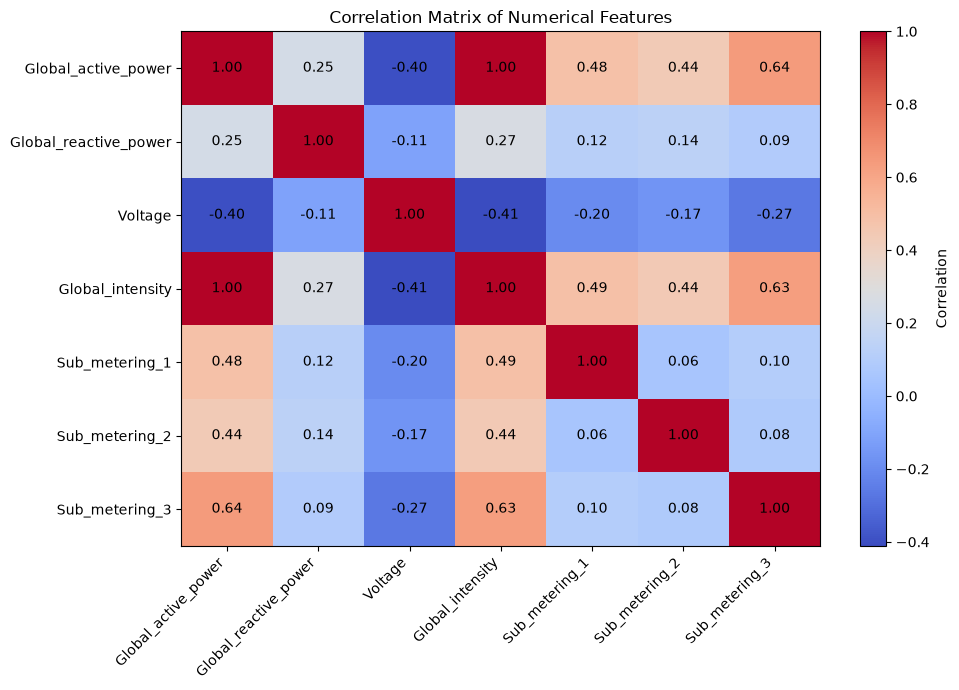

In [31]:
plt.figure(figsize= (10, 7))
plt.imshow(correlation_matrix, cmap= 'coolwarm', aspect= 'auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(correlation_matrix.columns)),
          correlation_matrix.columns,
          ha= 'right', rotation= 45)
plt.yticks(range(len(correlation_matrix.columns)), 
           correlation_matrix.columns)
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j,i,f'{correlation_matrix.iloc[i, j]:.2f}', ha='center',va='center')
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()

## Convert Date and Time to Datetime

The `Date` and `Time` columns were originally stored as object (string) data types.

Since this project involves time-series analysis, these columns were combined and converted into a single `datetime` column. This provides a proper temporal representation of each observation and makes it easier to extract useful time-based features in later stages.

The original `Date` and `Time` columns were then removed to avoid keeping redundant representations of the same information.

In [32]:
power_ds['datetime'] = pd.to_datetime(power_ds['Date'] + " " + power_ds['Time'], dayfirst= True)
power_ds.drop(columns= ['Date', 'Time'], inplace= True)
power_ds.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,datetime
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


## Extract Temporal Features

After creating the `datetime` column, several temporal features were extracted from it, including:

- **Year** — the year of the observation.
- **Month** — the month of the observation.
- **Day** — the day of the month.
- **Hour** — the hour of the observation.
- **Minute** — the minute of the observation.
- **DayOfWeek** — the day of the week, represented as a numerical value from 0 (Monday) to 6 (Sunday).

These features provide the model with explicit information about the temporal characteristics of electricity consumption.

Additional time-based features, such as the day of the week, weekend indicators, and cyclical representations of time, can be added in later stages if they are useful for the forecasting task.

In [33]:
power_ds['Year'] = power_ds['datetime'].dt.year
power_ds['Month'] = power_ds['datetime'].dt.month
power_ds['Day'] = power_ds['datetime'].dt.day
power_ds['Hour'] = power_ds['datetime'].dt.hour
power_ds['Minute'] = power_ds['datetime'].dt.minute
power_ds['Day_of_week'] = power_ds['datetime'].dt.dayofweek
power_ds.drop(columns= ['datetime'], inplace= True)
power_ds.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Year,Month,Day,Hour,Minute,Day_of_week
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006,12,16,17,24,5
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006,12,16,17,25,5
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006,12,16,17,26,5
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006,12,16,17,27,5
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006,12,16,17,28,5


In [34]:
power_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 13 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
 7   Year                   int32  
 8   Month                  int32  
 9   Day                    int32  
 10  Hour                   int32  
 11  Minute                 int32  
 12  Day_of_week            int32  
dtypes: float64(7), int32(6)
memory usage: 158.3 MB
